# From PAT files to a dissolved-solute signal

What a PharmaPy user does with the IR spectra of a crystallization run, shown on one run of OABA
(seeded cooling, slow cool, high seed load; Nagy group, Purdue, October 2026). Only the package is used:

1. `PharmaPy.PATReaders` reads the instrument files.
2. `PharmaPy.PATSignals` turns each spectrum into one number that follows the dissolved solute, in one of two ways:
   - `band_height`, when the solute has a band the solvent leaves free;
   - `SpectralScore`, which uses the whole spectrum, when it has none.

OABA allows both, so this notebook runs both and compares them.

In [1]:
import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from PharmaPy import PATReaders, PATSignals

# Folder of one run: one .iCIR file, one .icFbrm file and the thermostat log.
RUN_FOLDER = Path(r"<folder of the run>")
THERMOSTAT_LOG = "expttsd1.csv"
# The thermostat log holds relative time only. Its start in local time is taken as the modification time of the
# log file minus its last time value. For this run it was not checked against another clock.
LOG_START_LOCAL = datetime.datetime(2026, 10, 28, 23, 41, 15)
UTC_OFFSET_H = -4.0  # [h] local time minus UTC on the day of the run
ZERO_CELSIUS = 273.15  # [K]

# Solvent only, slurry and dissolved; then the two signals; then two neutrals.
AQUA, BLUE, ORANGE, VIOLET, YELLOW, INK, MUTED = "#1baf7a", "#2a78d6", "#eb6834", "#6250d6", "#eda100", "#2b2a27", "#8a8882"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})


def between(values, window):
    """Return a mask of the values inside a window, both ends included."""
    return (values >= window[0]) & (values <= window[1])

## 1. Read the files

The readers return arrays. IR sample times are UTC and FBRM sample times are local time, so both are put on one
clock here: seconds since the thermostat log started.

In [2]:
(ir_file,), (fbrm_file,) = RUN_FOLDER.glob("*.iCIR"), RUN_FOLDER.glob("*.icFbrm")
ir = PATReaders.read_ic_spectra(ir_file)
fbrm = PATReaders.read_ic_fbrm(fbrm_file)
log = np.genfromtxt(RUN_FOLDER / THERMOSTAT_LOG, delimiter=",", skip_header=2)  # time [s], then jacket, liquid and setpoint [C]
log_time, log_temperature = log[:, 0], log[:, 2] + ZERO_CELSIUS  # [s], [K]

start_utc = LOG_START_LOCAL - datetime.timedelta(hours=UTC_OFFSET_H)
time = (ir.time - np.datetime64(start_utc, "us")) / np.timedelta64(1, "s")  # [s] of each spectrum
fbrm_time = (fbrm.time - np.datetime64(LOG_START_LOCAL, "us")) / np.timedelta64(1, "s")  # [s] of each FBRM sample
counts = fbrm.counts.sum(axis=1)  # [counts] over all chord lengths

wavenumber, absorbance = ir.wavenumber, ir.absorbance  # [cm-1], [-]
# Liquid temperature at each spectrum [K]. Spectra taken before the log started have none.
temperature = np.interp(time, log_time, log_temperature, left=np.nan, right=np.nan)

print("spectra %s on %g to %g cm-1, from %.0f to %.0f s" % (absorbance.shape, wavenumber.max(), wavenumber.min(), time[0], time[-1]))
print("FBRM samples %s, from %.0f to %.0f s" % (counts.shape, fbrm_time[0], fbrm_time[-1]))
print("temperature log from %.0f to %.0f s; spectra without a logged temperature: %d" % (log_time[0], log_time[-1], np.isnan(temperature).sum()))

spectra (769, 589) on 3000 to 648 cm-1, from -913 to 52983 s
FBRM samples (5392,), from -160 to 53824 s
temperature log from 1 to 60380 s; spectra without a logged temperature: 9


## 2. Look at the run and mark what is known

A signal needs moments where the state of the vessel is known. This run has three:

- **Solvent only.** The IR was started before the solid went in. No process note records this; it is read from the
  spectra themselves (section 4 shows the solute band is absent in the first five spectra).
- **Slurry at 20 °C.** The first hold, with steady particle counts.
- **All dissolved.** The counts fall to almost nothing during heating and stay there until the seed is added.
  This stretch covers the hold at 45 °C and the cooling to 37 °C.

seed added at 8423 s; counts in the slurry 1250, in the dissolved stretch 31
spectra per state: {'Solvent only': 5, 'Slurry, 20 °C': 21, 'All dissolved, 37 to 45 °C': 46}


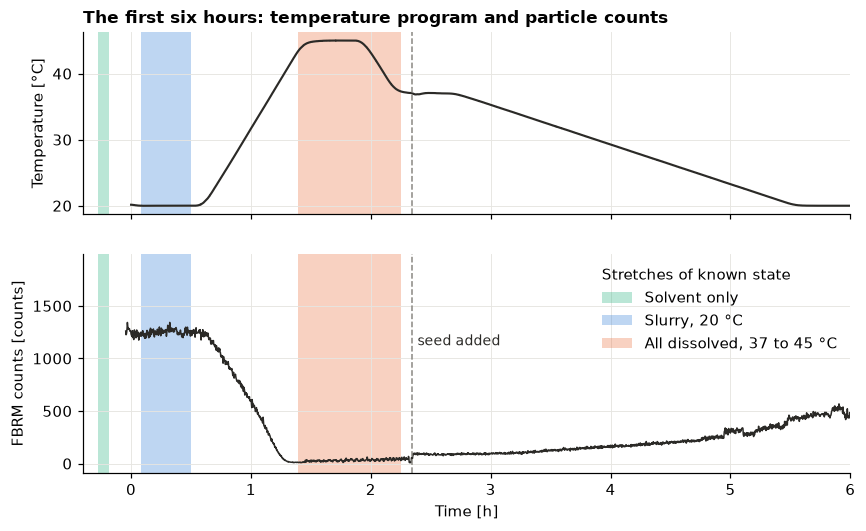

In [3]:
SOLVENT_ONLY = (-1000.0, -650.0)  # [s] before the solid was charged
SLURRY = (300.0, 1800.0)  # [s] hold at 20 C with solid present
DISSOLVED = (5000.0, 8100.0)  # [s] no particles; ends five minutes before the seed
# The seed is taken as the FBRM sample that ends the largest rise of the counts in the hold at 37 C.
in_hold = between(fbrm_time, (7900.0, 9600.0))
SEEDING = float(fbrm_time[in_hold][1:][np.argmax(np.diff(counts[in_hold]))])  # [s]
STATES = {"Solvent only": (SOLVENT_ONLY, AQUA), "Slurry, 20 °C": (SLURRY, BLUE), "All dissolved, 37 to 45 °C": (DISSOLVED, ORANGE)}

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, height_ratios=(1, 1.2))
top.plot(log_time / 3600, log_temperature - ZERO_CELSIUS, color=INK, lw=1.4)
bottom.plot(fbrm_time / 3600, counts, color=INK, lw=1.0)
for name, (window, colour) in STATES.items():
    for ax in (top, bottom):
        ax.axvspan(window[0] / 3600, window[1] / 3600, color=colour, alpha=0.3, lw=0, label=name)
bottom.legend(frameon=False, loc="upper right", title="Stretches of known state", alignment="left")
for ax in (top, bottom):
    ax.axvline(SEEDING / 3600, color=MUTED, lw=1.0, ls="--")
bottom.text(SEEDING / 3600 + 0.05, 0.9 * counts[between(fbrm_time, SLURRY)].mean(), "seed added", color=INK, fontsize=9)
top.set(ylabel="Temperature [°C]", title="The first six hours: temperature program and particle counts")
bottom.set(xlabel="Time [h]", ylabel="FBRM counts [counts]", xlim=(-0.4, 6.0))
print("seed added at %.0f s; counts in the slurry %.0f, in the dissolved stretch %.0f"
      % (SEEDING, np.median(counts[between(fbrm_time, SLURRY)]), np.median(counts[between(fbrm_time, DISSOLVED)])))
print("spectra per state:", {name: int(between(time, window).sum()) for name, (window, _) in STATES.items()})

## 3. Where does the solute show?

Average the spectra of each state and compare. The lower panel is the dissolved spectrum minus the solvent-only
spectrum: what the solute adds. A good band for the height is a peak there that stands alone, with a quiet
stretch on each side for the baseline anchors.

The largest feature, near 1630 cm$^{-1}$, sits on the strongest solvent band, which also changes with temperature,
so it is not used. The peak at 1236 cm$^{-1}$ stands alone between two minima, at 1264 and 1192 cm$^{-1}$.

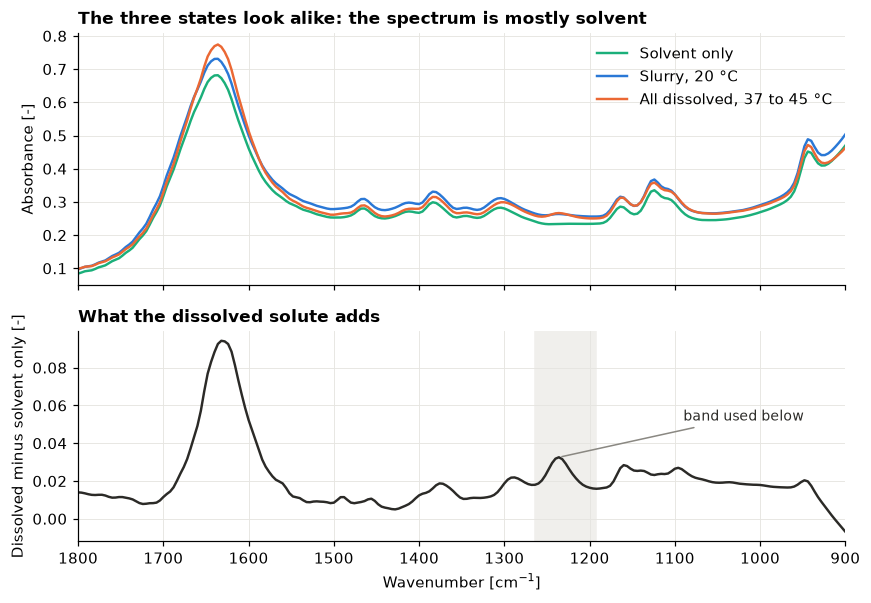

In [4]:
mean_spectrum = {name: absorbance[between(time, window)].mean(axis=0) for name, (window, _) in STATES.items()}
solvent_name, slurry_name, dissolved_name = STATES
added = mean_spectrum[dissolved_name] - mean_spectrum[solvent_name]  # [-]
PEAK, ANCHORS = 1236.0, (1264.0, 1192.0)  # [cm-1] the peak near 1240 and the minima beside it, read from the lower panel

shown = between(wavenumber, (900.0, 1800.0))
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.0), sharex=True, height_ratios=(1.2, 1))
for name, (_, colour) in STATES.items():
    top.plot(wavenumber[shown], mean_spectrum[name][shown], color=colour, lw=1.6, label=name)
top.set(ylabel="Absorbance [-]", title="The three states look alike: the spectrum is mostly solvent")
top.legend(frameon=False)
bottom.axvspan(ANCHORS[0], ANCHORS[1], color="#f0efec", zorder=0)
bottom.plot(wavenumber[shown], added[shown], color=INK, lw=1.6)
bottom.annotate("band used below", xy=(PEAK, added[np.argmin(np.abs(wavenumber - PEAK))]), xytext=(1090, 0.052), color=INK, fontsize=9,
                arrowprops={"arrowstyle": "-", "color": MUTED})
bottom.set(xlabel="Wavenumber [cm$^{-1}$]", ylabel="Dissolved minus solvent only [-]", title="What the dissolved solute adds")
bottom.set_xlim(1800, 900);

## 4. Band height: one call

`band_height` reads the absorbance at the peak and subtracts a straight baseline drawn through the two anchors.
Peak and anchors belong to the compound and solvent; the user reads them from the figure above.

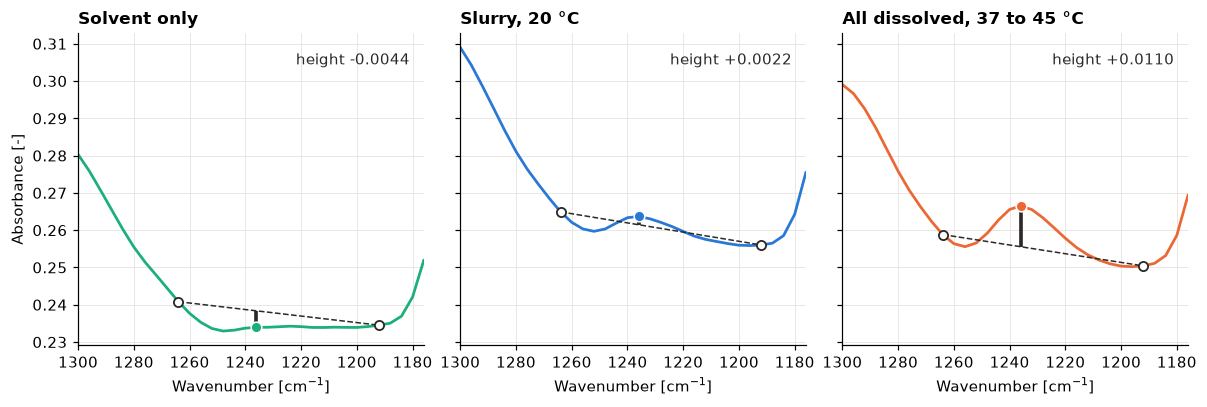

In [5]:
height = PATSignals.band_height(wavenumber, absorbance, PEAK, ANCHORS)  # [-] one value per spectrum

zoom = between(wavenumber, (1176.0, 1300.0))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (name, (_, colour)) in zip(axes, STATES.items()):
    spectrum = mean_spectrum[name]
    at = {position: float(spectrum[np.argmin(np.abs(wavenumber - position))]) for position in (*ANCHORS, PEAK)}  # [-]
    baseline_at_peak = at[ANCHORS[0]] + (at[ANCHORS[1]] - at[ANCHORS[0]]) * (PEAK - ANCHORS[0]) / (ANCHORS[1] - ANCHORS[0])  # [-]
    ax.plot(wavenumber[zoom], spectrum[zoom], color=colour, lw=1.8)
    ax.plot(ANCHORS, [at[ANCHORS[0]], at[ANCHORS[1]]], color=INK, lw=1.0, ls="--")
    ax.plot(ANCHORS, [at[ANCHORS[0]], at[ANCHORS[1]]], "o", color="white", mec=INK, mew=1.2, ms=6)
    ax.plot([PEAK, PEAK], [baseline_at_peak, at[PEAK]], color=INK, lw=2.4, solid_capstyle="butt")
    ax.plot([PEAK], [at[PEAK]], "o", color=colour, mec="white", ms=7)
    ax.text(0.96, 0.9, "height %+.4f" % (at[PEAK] - baseline_at_peak), transform=ax.transAxes, color=INK, fontsize=10, ha="right")
    ax.set_xlim(1300, 1176)
    ax.set(xlabel="Wavenumber [cm$^{-1}$]", title=name)
axes[0].set_ylabel("Absorbance [-]")
fig.tight_layout()

The band is absent in the solvent, small in the slurry and largest with everything dissolved. Over the whole
run the height follows the dissolved solute: up while the solid dissolves, flat while everything is dissolved,
down as the seeded solution crystallizes on cooling, flat again at 20 °C.

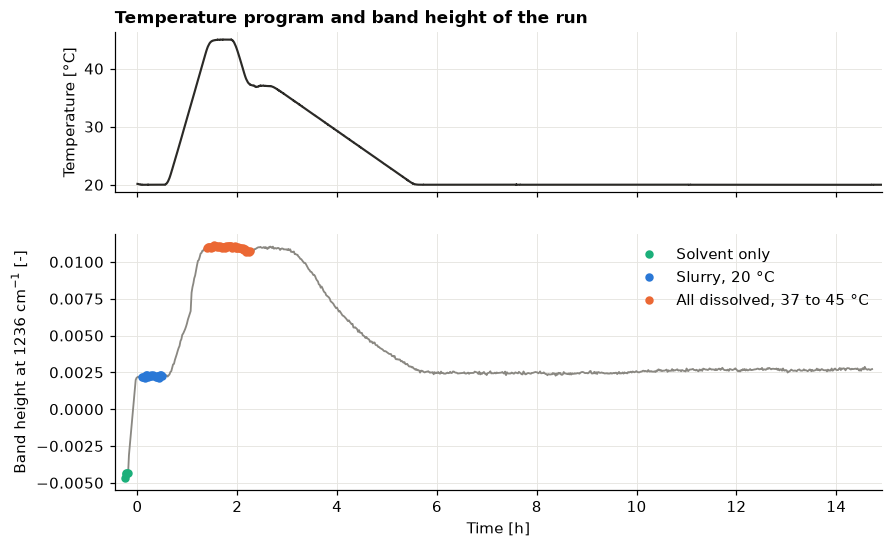

In [6]:
level = {name: float(height[between(time, window)].mean()) for name, (window, _) in STATES.items()}  # [-]
step = level[dissolved_name] - level[slurry_name]  # [-] slurry to dissolved

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=(1, 1.6))
top.plot(log_time / 3600, log_temperature - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [°C]", title="Temperature program and band height of the run")
bottom.plot(time / 3600, height, color=MUTED, lw=1.2)
for name, (window, colour) in STATES.items():
    inside = between(time, window)
    bottom.plot(time[inside] / 3600, height[inside], "o", color=colour, ms=4.5, label=name)
bottom.set(xlabel="Time [h]", ylabel="Band height at %.0f cm$^{-1}$ [-]" % PEAK, xlim=(time[0] / 3600 - 0.2, time[-1] / 3600 + 0.2))
bottom.legend(frameon=False, loc="upper right");

Three checks a user can make without any other measurement:

- **Noise.** The scatter in the slurry hold, where nothing changes.
- **Temperature.** In the dissolved stretch the composition is constant while the temperature moves between 37
  and 45 °C. A good signal stays flat there.
- **Return.** Back at 20 °C with solid present, the solution should end where the slurry started, if it has had
  time to come to equilibrium.

In [7]:
in_dissolved = between(time, DISSOLVED)
per_kelvin = np.polyfit(temperature[in_dissolved], height[in_dissolved], 1)[0]  # [1/K]
kelvin = np.ptp(temperature[in_dissolved])  # [K]
back_at_20 = (time > SEEDING) & (np.abs(temperature - (20.0 + ZERO_CELSIUS)) < 0.05)
first_half_hour = back_at_20 & (time < time[back_at_20][0] + 1800.0)
last_half_hour = time > time[-1] - 1800.0


def as_fraction(values):
    """Return a signal on the scale 0 = all dissolved, -1 = slurry at the start."""
    return (values - level[dissolved_name]) / step


print("band height: solvent only %+.4f, slurry %+.4f, all dissolved %+.4f" % tuple(level.values()))
print("noise in the slurry hold        : %.1f %% of the slurry-to-dissolved step" % (100 * height[between(time, SLURRY)].std() / step))
print("change over %.1f K, all dissolved : %.1f %% of the step" % (kelvin, 100 * per_kelvin * kelvin / step))
print("first half hour back at 20 C    : %+.2f on the scale 0 = dissolved, -1 = starting slurry" % as_fraction(height[first_half_hour]).mean())
print("last half hour of the run       : %+.2f" % as_fraction(height[last_half_hour]).mean())

band height: solvent only -0.0044, slurry +0.0022, all dissolved +0.0110
noise in the slurry hold        : 0.7 % of the slurry-to-dissolved step
change over 7.7 K, all dissolved : 3.6 % of the step
first half hour back at 20 C    : -0.97 on the scale 0 = dissolved, -1 = starting slurry
last half hour of the run       : -0.94


## 5. Whole-spectrum score: fit, then apply

Without a free band, `SpectralScore` uses every point of a spectral window. It works in two steps.

- **`fit`** learns from a reference run, given as three selections of its spectra: a clear solution of one
  composition at several temperatures (how temperature alone changes the spectrum), the dissolved charge
  (score 0) and a slurry (score −1).
- **`score`** then reads the spectra of any run of the same solute, solvent and probe. It returns the score and
  three terms that take up a change of probe contact: scale, offset and tilt.

Here the dissolved stretch serves twice, as the clear solution and as the zero. The score needs a temperature
for every spectrum, so the spectra taken before the log started are left out.

In [8]:
logged = np.isfinite(temperature)
run_time, run_temperature, run_spectra = time[logged], temperature[logged], absorbance[logged]
WINDOW = (900.0, 1800.0)  # [cm-1] where the solute bands of section 3 lie
MAXIMUM_ABSORBANCE = 1.3  # [-] points on stronger bands are left out; a design choice, and no point of this run exceeds it
REFERENCE_TEMPERATURE = 37.0 + ZERO_CELSIUS  # [K] the seeding temperature; every spectrum is moved to it

fitted = PATSignals.SpectralScore.fit(
    wavenumber, run_spectra, run_temperature,
    clear_solution=between(run_time, DISSOLVED), dissolved=between(run_time, DISSOLVED), slurry=between(run_time, SLURRY),
    reference_temperature=REFERENCE_TEMPERATURE, window=WINDOW, maximum_absorbance=MAXIMUM_ABSORBANCE)
terms = fitted.score(wavenumber, run_spectra, run_temperature, dissolved=between(run_time, DISSOLVED))

coldest = run_temperature.min()  # [K]
outside = fitted.temperature_range[0] - coldest  # [K] below the temperatures the temperature effect was fitted on
print("spectral points used: %d of %d" % (fitted.usable.sum(), wavenumber.size))
print("temperature effect fitted between %.1f and %.1f C; the run goes down to %.1f C, %.0f K outside"
      % (fitted.temperature_range[0] - ZERO_CELSIUS, fitted.temperature_range[1] - ZERO_CELSIUS, coldest - ZERO_CELSIUS, outside))
print("score that rests on that extrapolation at %.0f C: %.2f" % (coldest - ZERO_CELSIUS, abs(fitted.score_per_kelvin) * outside))

spectral points used: 226 of 589
temperature effect fitted between 37.3 and 45.0 C; the run goes down to 20.0 C, 17 K outside
score that rests on that extrapolation at 20 C: 0.16


Both signals on one scale: 0 is the dissolved charge, −1 the slurry at the start of the run.

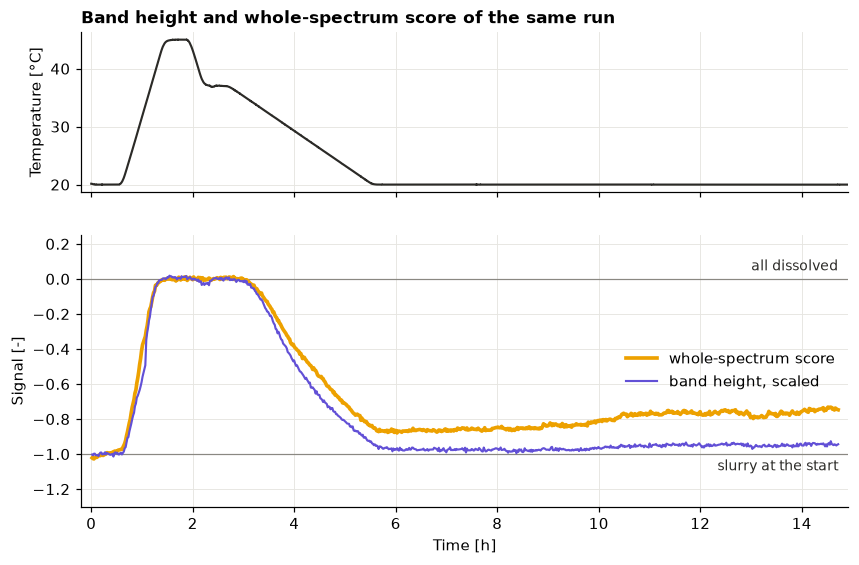

In [9]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, height_ratios=(1, 1.7))
top.plot(log_time / 3600, log_temperature - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [°C]", title="Band height and whole-spectrum score of the same run")
bottom.axhline(0.0, color=MUTED, lw=0.8)
bottom.axhline(-1.0, color=MUTED, lw=0.8)
bottom.plot(run_time / 3600, terms.score, color=YELLOW, lw=2.4, label="whole-spectrum score")
bottom.plot(time[time > 0] / 3600, as_fraction(height[time > 0]), color=VIOLET, lw=1.4, label="band height, scaled")
bottom.text(time[-1] / 3600, 0.03, "all dissolved", color=INK, fontsize=9, ha="right", va="bottom")
bottom.text(time[-1] / 3600, -1.03, "slurry at the start", color=INK, fontsize=9, ha="right", va="top")
bottom.set(xlabel="Time [h]", ylabel="Signal [-]", ylim=(-1.3, 0.25), xlim=(-0.2, time[-1] / 3600 + 0.2))
bottom.legend(frameon=False, loc="center right");

The same checks for both signals, and one more: the result should not hinge on a choice the user made. For
the band height that choice is the peak position, moved here by one spectral point either way. For the score it
is the spectral window, narrowed here in a second fit.

In [10]:
narrow = PATSignals.SpectralScore.fit(
    wavenumber, run_spectra, run_temperature,
    clear_solution=between(run_time, DISSOLVED), dissolved=between(run_time, DISSOLVED), slurry=between(run_time, SLURRY),
    reference_temperature=REFERENCE_TEMPERATURE, window=(1100.0, 1750.0), maximum_absorbance=MAXIMUM_ABSORBANCE)
narrow_terms = narrow.score(wavenumber, run_spectra, run_temperature, dissolved=between(run_time, DISSOLVED))



def scaled_height(peak):
    """Return the band height at another peak position on the scale 0 = all dissolved, -1 = slurry at the start."""
    values = PATSignals.band_height(wavenumber, absorbance, peak, ANCHORS)
    dissolved_level, slurry_level = values[between(time, DISSOLVED)].mean(), values[between(time, SLURRY)].mean()
    return ((values - dissolved_level) / (dissolved_level - slurry_level))[logged]


spacing = float(np.abs(np.diff(wavenumber)).mean())  # [cm-1] between spectral points
signals = {"band height at %.0f cm-1" % PEAK: as_fraction(height[logged]),
           "band height at %.0f cm-1" % (PEAK - spacing): scaled_height(PEAK - spacing),
           "band height at %.0f cm-1" % (PEAK + spacing): scaled_height(PEAK + spacing),
           "score, %.0f to %.0f cm-1" % WINDOW: terms.score,
           "score, 1100 to 1750 cm-1": narrow_terms.score}
print("%-28s %10s %14s %12s" % ("", "noise", "back at 20 C", "end of run"))
for name, signal in signals.items():
    print("%-28s %10.3f %+14.2f %+12.2f" % (name, signal[between(run_time, SLURRY)].std(),
                                          signal[first_half_hour[logged]].mean(), signal[last_half_hour[logged]].mean()))
lowest = int(np.argmin(terms.scale))
print("contact terms of the score over the run: scale %+.3f to %+.3f, offset %+.3f to %+.3f, tilt %+.3f to %+.3f"
      % (terms.scale.min(), terms.scale.max(), terms.offset.min(), terms.offset.max(), terms.tilt.min(), terms.tilt.max()))
print("largest loss of signal: scale %+.3f at %.2f h" % (terms.scale[lowest], run_time[lowest] / 3600))
print("part of the 20 C score that rests on the extrapolated temperature effect: %.2f (900 to 1800), %.2f (1100 to 1750)"
      % (abs(fitted.score_per_kelvin) * outside, abs(narrow.score_per_kelvin) * outside))

                                  noise   back at 20 C   end of run
band height at 1236 cm-1          0.007          -0.97        -0.94
band height at 1232 cm-1          0.007          -0.96        -0.90
band height at 1240 cm-1          0.007          -0.98        -1.01
score, 900 to 1800 cm-1           0.010          -0.87        -0.74
score, 1100 to 1750 cm-1          0.011          -0.98        -0.96
contact terms of the score over the run: scale -0.074 to +0.007, offset -0.002 to +0.008, tilt -0.013 to +0.001
largest loss of signal: scale -0.074 at 1.01 h
part of the 20 C score that rests on the extrapolated temperature effect: 0.16 (900 to 1800), 0.71 (1100 to 1750)


## 6. Reading the result

- **The band height passes its checks.** Its noise is 0.7 % of the slurry-to-dissolved step. With everything
  dissolved it changes by 3.6 % of the step over 7.7 K. Back at 20 °C it reads −0.97, close to the slurry the run
  started from, and one spectral point either way moves that by 0.01.
- **The score follows the same curve and is less certain at 20 °C in this run.** The two windows read −0.87 and
  −0.98 back at 20 °C, and −0.74 and −0.96 at the end. The cause is in the fit. A seeded solution crystallizes as
  it cools, so this run has no clear solution below 37 °C. The temperature effect is fitted between 37 and 45 °C
  and carried 17 K further down. `score_per_kelvin` sizes this: 0.16 of the score at 20 °C in the wide window and
  0.71 in the narrow one rest on that extrapolation.
- **The contact terms show what the probe did.** Near 1.0 h the whole spectrum dropped by about 7 %, which the
  score reports as `scale`. The band height shows a kink there: a baseline removes a shift of the spectrum, not a
  loss of signal.
- **The values at the end of the run are less firm than those at the start of the hold.** Over the nine hours
  at 20 °C both signals drift slowly, and one spectral point moves the final band height between −0.90 and −1.01.
  The cause of the drift is not established.

For OABA the band height is the signal to use. The score is the route for a solute without a free band; its
reference run should then hold a clear solution over the whole temperature range of the process.

## 7. Not yet a concentration

Neither signal is a concentration. A first reading is possible here because the run has solvent-only spectra:

In [11]:
dissolved_at_20 = (level[slurry_name] - level[solvent_name]) / (level[dissolved_name] - level[solvent_name])  # [-]
print("band height of the slurry, as a fraction of the height with the whole charge dissolved: %.2f" % dissolved_at_20)

band height of the slurry, as a fraction of the height with the whole charge dissolved: 0.43


If the height is proportional to the dissolved solute and does not depend on temperature, 43 % of the
charge is dissolved at 20 °C. Both are assumptions until a calibration checks them, and a calibration in kg of
solute per kg of solvent needs the charged masses, which are not in the run folder.

**Another run.** The band height is the same call on the other run's spectra. For the score the fit is not
repeated: `fitted.score(wavenumber, spectra, temperature, dissolved=...)` takes the other run's spectra, their
temperatures and that run's own dissolved stretch.